In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline

from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import train_test_split

from sklearn.model_selection import KFold 
from sklearn.model_selection import GridSearchCV

from sklearn.ensemble import RandomForestClassifier 

from sklearn.naive_bayes import GaussianNB

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier

from sklearn import svm

from sklearn import metrics # for the check the error and accuracy of the model

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
#from sklearn.metrics import roc_auc_score, plot_confusion_matrix, plot_roc_curve

from sklearn.preprocessing import StandardScaler

import random
import time
import math
import benchmarks

# Any results you write to the current directory are saved as output.
# dont worry about the error if its not working then insteda of model_selection we can use cross_validation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn import preprocessing
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier as rf
from sklearn.preprocessing import StandardScaler
#from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, plot_confusion_matrix, plot_roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.ensemble import AdaBoostClassifier
from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions
import matplotlib.gridspec as gridspec
import itertools
#import eli5
#from eli5.sklearn import PermutationImportance
import statsmodels.api as sm
import time
import warnings
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
warnings.filterwarnings("ignore")

In [3]:
data = pd.read_csv('ckd.csv',sep=',', na_values=['?'])

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    object 
 21  appet   399 non-null    object 
 22  pe

In [5]:
data.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [ ]:
import sys
!{sys.executable} -m pip install seaborn


In [ ]:
import sys
!{sys.executable} -m pip uninstall seaborn
!{sys.executable} -m pip install seaborn

In [9]:
sns.countplot(data['class'],label="Count")

KeyError: 0

# Preprocessing

In [7]:
data.replace('?',-99999, inplace=True)
data.dropna(inplace = True)

In [8]:
data['class']=data['class'].map({'ckd':1,'notckd':0})

In [11]:
data['rbc']=data['rbc'].map({'normal':0,'abnormal':1})

In [12]:
data['pc']=data['pc'].map({'normal':0,'abnormal':1})

In [13]:
data['pcc']=data['pcc'].map({'present':0,'notpresent':1})

In [14]:
data['ba']=data['ba'].map({'present':1,'notpresent':0})

In [16]:
data['htn']=data['htn'].map({'yes':1,'no':0})

In [17]:
data['dm']=data['dm'].map({'yes':1,'no':0})

In [18]:
data['cad']=data['cad'].map({'yes':1,'no':0})

In [19]:
data['appet']=data['appet'].map({'good':0,'poor':1})

In [20]:
data['pe']=data['pe'].map({'yes':1,'no':0})

In [21]:
data['ane']=data['ane'].map({'yes':1,'no':0})

In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158 entries, 3 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     158 non-null    float64
 1   bp      158 non-null    float64
 2   sg      158 non-null    float64
 3   al      158 non-null    float64
 4   su      158 non-null    float64
 5   rbc     158 non-null    int64  
 6   pc      158 non-null    int64  
 7   pcc     158 non-null    int64  
 8   ba      158 non-null    int64  
 9   bgr     158 non-null    float64
 10  bu      158 non-null    float64
 11  sc      158 non-null    float64
 12  sod     158 non-null    float64
 13  pot     158 non-null    float64
 14  hemo    158 non-null    float64
 15  pcv     158 non-null    float64
 16  wbcc    158 non-null    float64
 17  rbcc    158 non-null    float64
 18  htn     0 non-null      float64
 19  dm      158 non-null    int64  
 20  cad     158 non-null    int64  
 21  appet   158 non-null    int64  
 22  pe     

In [23]:
y1=data['class']
x1=data.drop(['class'],axis=1)

In [24]:
x1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158 entries, 3 to 399
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     158 non-null    float64
 1   bp      158 non-null    float64
 2   sg      158 non-null    float64
 3   al      158 non-null    float64
 4   su      158 non-null    float64
 5   rbc     158 non-null    int64  
 6   pc      158 non-null    int64  
 7   pcc     158 non-null    int64  
 8   ba      158 non-null    int64  
 9   bgr     158 non-null    float64
 10  bu      158 non-null    float64
 11  sc      158 non-null    float64
 12  sod     158 non-null    float64
 13  pot     158 non-null    float64
 14  hemo    158 non-null    float64
 15  pcv     158 non-null    float64
 16  wbcc    158 non-null    float64
 17  rbcc    158 non-null    float64
 18  htn     0 non-null      float64
 19  dm      158 non-null    int64  
 20  cad     158 non-null    int64  
 21  appet   158 non-null    int64  
 22  pe     

In [25]:
bestfeatures = SelectKBest(score_func=chi2, k=10)
fit = bestfeatures.fit(x1,y1)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(x1.columns)

featureScores = pd.concat([dfcolumns, dfscores], axis=1)
featureScores.columns = ['Specs', 'Score']
featureScores

ValueError: Input X contains NaN.
SelectKBest does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [23]:
# 10 best features
featureScores.nlargest(10, 'Score')

,Specs,Score
16,wbcc,30084.148308
10,bu,3079.959561
9,bgr,1762.030281
3,al,336.976744
11,sc,335.034935
15,pcv,212.873055
4,su,106.976744
18,htn,90.930233
6,pc,77.558140
19,dm,74.883721


# Correlations

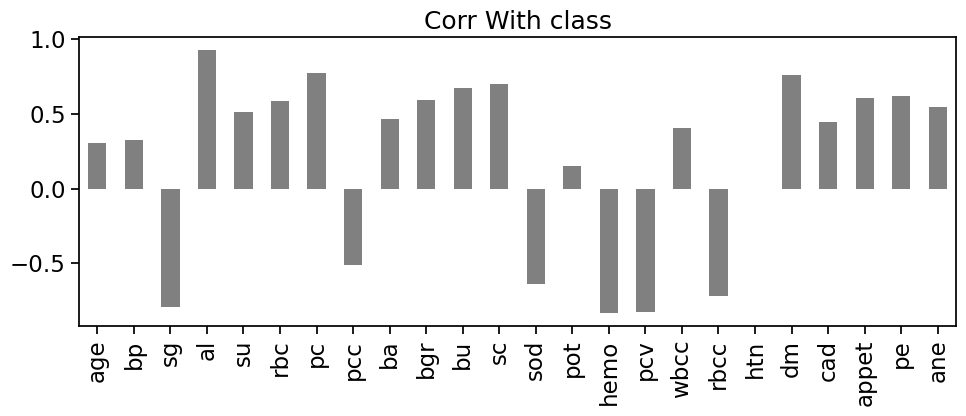

In [36]:
sns.set_context('notebook',font_scale=1.5)
c1=x1.corrwith(y1)
c1.plot(kind='bar',grid=False,color='gray',figsize=(10,4.5),title="Corr With class")
plt.tight_layout()

In [25]:
corr_mat=data.corr('pearson')
plt.figure(figsize=(40,40))
corr_mat.style.background_gradient(cmap='coolwarm')
#sns.heatmap(corr_mat, cbar=True,square = True, annot=True, fmt= '.2f',annot_kws={'size': 14},cmap= 'coolwarm')

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
age,1.000000,0.079712,-0.277303,0.253380,0.207711,0.147971,0.188907,-0.124032,0.068353,0.301915,0.190636,0.189721,-0.102933,0.006866,-0.245645,-0.235116,0.153132,-0.242235,0.372348,0.323957,0.269868,0.170259,0.232327,0.105809,0.305119
bp,0.079712,1.000000,-0.198897,0.322507,0.243828,0.316670,0.179834,-0.206507,0.174555,0.190113,0.316287,0.386551,-0.224710,0.127801,-0.282365,-0.353504,0.008274,-0.228533,0.334951,0.218096,0.257709,0.145047,0.117878,0.311097,0.326567
sg,-0.277303,-0.198897,1.000000,-0.712331,-0.448477,-0.500494,-0.630323,0.460050,-0.516392,-0.544781,-0.545319,-0.563122,0.539285,-0.075057,0.682086,0.678472,-0.288930,0.619092,-0.648168,-0.639391,-0.379305,-0.523944,-0.633622,-0.413252,-0.790102
al,0.253380,0.322507,-0.712331,1.000000,0.521448,0.489941,0.752956,-0.503341,0.516104,0.518123,0.661940,0.702889,-0.599334,0.209492,-0.784745,-0.775528,0.314574,-0.640099,0.796876,0.678582,0.374755,0.578080,0.622268,0.569529,0.925816
su,0.207711,0.243828,-0.448477,0.521448,1.000000,0.256568,0.335901,-0.177327,0.381929,0.730050,0.312259,0.347196,-0.242491,0.271954,-0.385511,-0.404821,0.201000,-0.377726,0.577286,0.591010,0.466658,0.220547,0.374128,0.179811,0.510615
rbc,0.147971,0.316670,-0.500494,0.489941,0.256568,1.000000,0.498959,-0.168592,0.273177,0.493857,0.378478,0.410408,-0.344916,-0.019319,-0.452566,-0.422537,0.108857,-0.379378,0.442400,0.511777,0.293269,0.418639,0.282868,0.209797,0.586391
pc,0.188907,0.179834,-0.630323,0.752956,0.335901,0.498959,1.000000,-0.600092,0.481227,0.430646,0.613318,0.588517,-0.520324,0.176150,-0.733140,-0.718042,0.169936,-0.667113,0.666767,0.636288,0.384223,0.528435,0.606234,0.545380,0.775388
pcc,-0.124032,-0.206507,0.460050,-0.503341,-0.177327,-0.168592,-0.600092,1.000000,-0.415033,-0.257768,-0.366726,-0.361965,0.473954,0.030297,0.531182,0.534564,-0.146742,0.499401,-0.432876,-0.321900,-0.352255,-0.432515,-0.350171,-0.485941,-0.509915
ba,0.068353,0.174555,-0.516392,0.516104,0.381929,0.273177,0.481227,-0.415033,1.000000,0.318095,0.205351,0.229238,-0.221374,-0.000279,-0.410353,-0.397500,0.170071,-0.343299,0.314961,0.367477,0.297063,0.187815,0.393819,0.141344,0.468845
bgr,0.301915,0.190113,-0.544781,0.518123,0.730050,0.493857,0.430646,-0.257768,0.318095,1.000000,0.326496,0.331284,-0.284968,0.102226,-0.434158,-0.443818,0.212093,-0.418085,0.579407,0.663012,0.459164,0.338924,0.336141,0.139854,0.591217


<Figure size 2880x2880 with 0 Axes>

In [26]:
data.columns

Index(['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu',
       'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'class'],
      dtype='object')

In [27]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

n=42
m=0.20

x1_train, x1_test, y1_train, y1_test = train_test_split(x1, y1, test_size=m, random_state=n)

# Random Forest

classification Report:-
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         9

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

Accuracy= 1.0


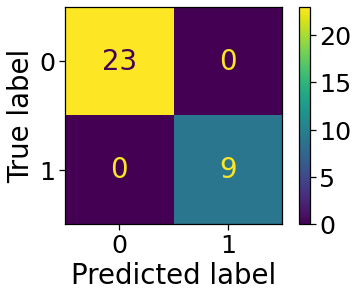

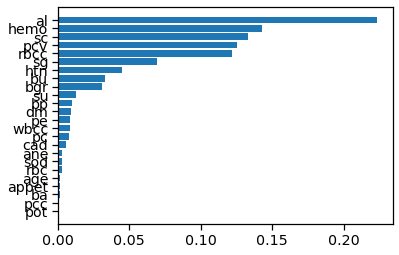

In [28]:
#clf = RandomForestClassifier(criterion='gini',max_depth=10,max_leaf_nodes=4)
clf = RandomForestClassifier()
z1=clf.fit(x1_train,y1_train)
pred1 = clf.predict(x1_test)
AS1=accuracy_score(y1_test, pred1)
CR1=classification_report(y1_test,pred1)
result1 = confusion_matrix(y1_test, pred1)

print("classification Report:-")     
print(CR1)
print("Accuracy=",AS1)

plot_confusion_matrix(clf, x1_test, y1_test) 

importances = clf.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1.3)

fig, ax = plt.subplots()
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x1_train.columns)[indices])

In [29]:
feats = {}
for feature,importance in zip(x1.columns, clf.feature_importances_):
    feats[feature] = importance

importances = pd.DataFrame.from_dict(feats, orient='index')
importances.columns = ['importance']
importances = importances.sort_values(by='importance', ascending=False)
importances = importances.reset_index()
importances = importances.rename(columns={'index':'features'})
importances

,features,importance
0,al,0.223182
1,hemo,0.142736
2,sc,0.133114
3,pcv,0.125244
4,rbcc,0.122190
5,sg,0.069214
6,htn,0.044794
7,bu,0.032831
8,bgr,0.030644
9,su,0.012532


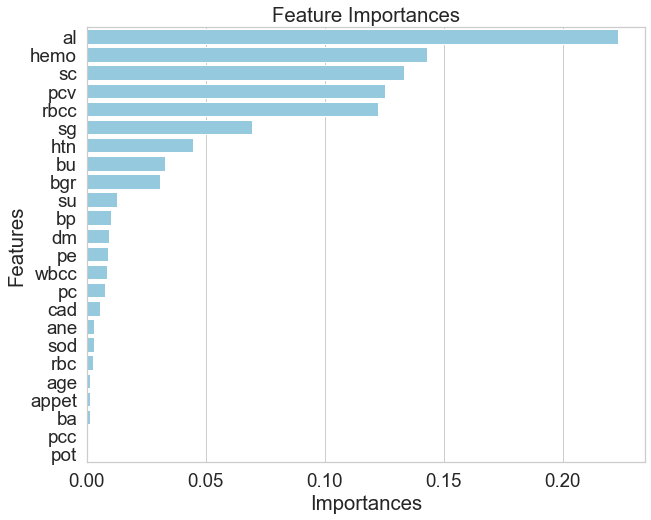

In [30]:
sns.set(font_scale=5)
sns.set(style='whitegrid', color_codes=True, font_scale=1.7)
fig, ax = plt.subplots()
fig.set_size_inches(10, 8)
sns.barplot(x=importances['importance'], y = importances['features'], 
            data= importances, color='skyblue')
plt.xlabel('Importances')
plt.ylabel('Features')
plt.title('Feature Importances')
plt.show()

# xGBoosting

classification Report:-
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         9

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

Accuracy= 1.0


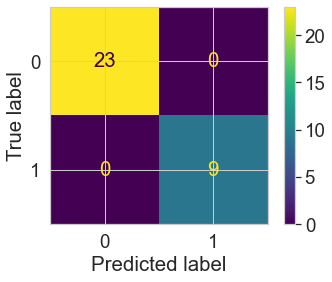

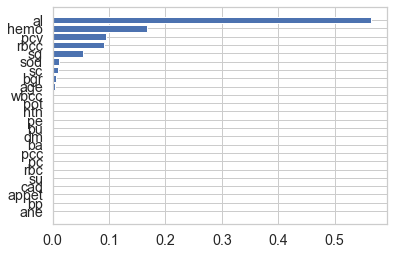

In [31]:
clfg = XGBClassifier(verbosity=0,bool=True)
zg1=clfg.fit(x1_train,y1_train)
predg1 = clfg.predict(x1_test)
ASg1=accuracy_score(y1_test, predg1)
CRg1=classification_report(y1_test,predg1)
resultg1 = confusion_matrix(y1_test, predg1)

print("classification Report:-")     
print(CRg1)
print("Accuracy=",ASg1)

plot_confusion_matrix(clfg, x1_test, y1_test) 

importances = clfg.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1.3)

fig, ax = plt.subplots()
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x1_train.columns)[indices])

In [32]:
feats = {}
for feature,importance in zip(x1.columns, clfg.feature_importances_):
    feats[feature] = importance

importances = pd.DataFrame.from_dict(feats, orient='index')
importances.columns = ['importance']
importances = importances.sort_values(by='importance', ascending=False)
importances = importances.reset_index()
importances = importances.rename(columns={'index':'features'})
importances

,features,importance
0,al,0.565093
1,hemo,0.166535
2,pcv,0.094160
3,rbcc,0.090716
4,sg,0.053190
5,sod,0.011530
6,sc,0.008871
7,bgr,0.006306
8,age,0.003599
9,ba,0.000000


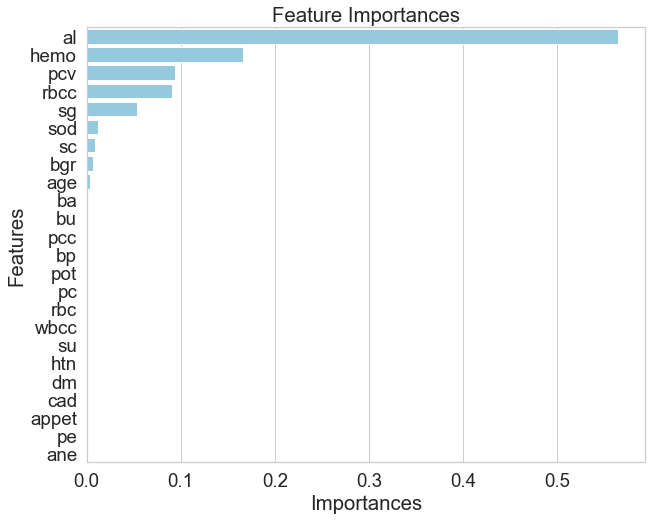

In [33]:
sns.set(font_scale=5)
sns.set(style='whitegrid', color_codes=True, font_scale=1.7)
fig, ax = plt.subplots()
fig.set_size_inches(10, 8)
sns.barplot(x=importances['importance'], y = importances['features'], 
            data= importances, color='skyblue')
plt.xlabel('Importances')
plt.ylabel('Features')
plt.title('Feature Importances')
plt.show()

# SVM

classification Report:-
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        23
           1       1.00      0.89      0.94         9

    accuracy                           0.97        32
   macro avg       0.98      0.94      0.96        32
weighted avg       0.97      0.97      0.97        32

Accuracy= 0.96875


AttributeError: 'SVC' object has no attribute 'feature_importances_'

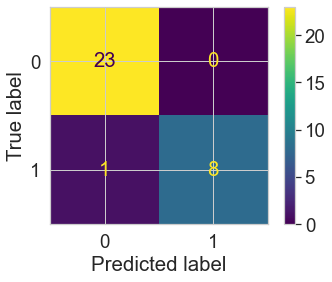

In [34]:
from sklearn.svm import SVC

cls=SVC(kernel="linear",C=1)
zv1=cls.fit(x1_train,y1_train)
predv1 = cls.predict(x1_test)
ASv1=accuracy_score(y1_test, predv1)
CRv1=classification_report(y1_test,predv1)
resultv1 = confusion_matrix(y1_test, predv1)
print("classification Report:-")     
print(CRv1)
print("Accuracy=",ASv1)


plot_confusion_matrix(cls, x1_test, y1_test) 

importances = cls.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1.3)

fig, ax = plt.subplots()
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x1_train.columns)[indices])

# AdaBoosting 

classification Report:-
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         9

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

Accuracy= 1.0


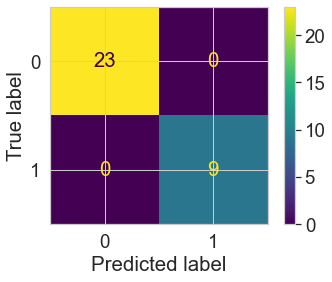

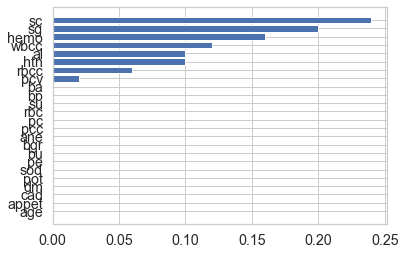

In [35]:
from sklearn.ensemble import AdaBoostClassifier
cls=AdaBoostClassifier()
zada1=cls.fit(x1_train,y1_train)
predAB1 = cls.predict(x1_test)
ASAB1=accuracy_score(y1_test, predAB1)
CRAB1=classification_report(y1_test,predAB1)
resultAB1 = confusion_matrix(y1_test, predAB1)
print("classification Report:-")     
print(CRAB1)
print("Accuracy=",ASAB1)

plot_confusion_matrix(cls, x1_test, y1_test) 

importances = cls.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1.3)

fig, ax = plt.subplots()
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x1_train.columns)[indices])

In [36]:
feats = {}
for feature,importance in zip(x1.columns, cls.feature_importances_):
    feats[feature] = importance

importances = pd.DataFrame.from_dict(feats, orient='index')
importances.columns = ['importance']
importances = importances.sort_values(by='importance', ascending=False)
importances = importances.reset_index()
importances = importances.rename(columns={'index':'features'})
importances

,features,importance
0,sc,0.24
1,sg,0.20
2,hemo,0.16
3,wbcc,0.12
4,al,0.10
5,htn,0.10
6,rbcc,0.06
7,pcv,0.02
8,age,0.00
9,pe,0.00


# Naive Bayes Classifier

classification Report:-
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         9

    accuracy                           1.00        32
   macro avg       1.00      1.00      1.00        32
weighted avg       1.00      1.00      1.00        32

Accuracy= 1.0


AttributeError: 'GaussianNB' object has no attribute 'feature_importances_'

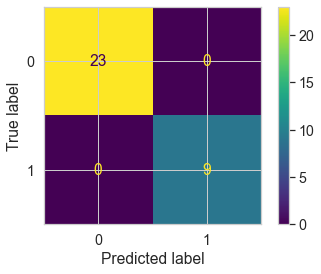

In [37]:
from sklearn.naive_bayes import GaussianNB
#params_nb = {}

#model_nb = GaussianNB(**params_nb)
#model_nb, accuracy_nb, roc_auc_nb, tt_nb = run_model(model_nb, X_train, y_train, X_test, y_test)

cls=GaussianNB()
zada1=cls.fit(x1_train,y1_train)
predNB1 = cls.predict(x1_test)
ASNB1=accuracy_score(y1_test, predNB1)
CRNB1=classification_report(y1_test,predNB1)
resultNB1 = confusion_matrix(y1_test, predNB1)
print("classification Report:-")     
print(CRNB1)
print("Accuracy=",ASNB1)

plot_confusion_matrix(cls, x1_test, y1_test) 

importances = cls.feature_importances_

indices = np.argsort(importances)
sns.set_context('notebook',font_scale=1.3)

fig, ax = plt.subplots()
ax.barh(range(len(importances)), importances[indices])
ax.set_yticks(range(len(importances)))
_ = ax.set_yticklabels(np.array(x1_train.columns)[indices])

In [38]:
feats = {}
for feature,importance in zip(x1.columns, cls.feature_importances_):
    feats[feature] = importance

importances = pd.DataFrame.from_dict(feats, orient='index')
importances.columns = ['importance']
importances = importances.sort_values(by='importance', ascending=False)
importances = importances.reset_index()
importances = importances.rename(columns={'index':'features'})
importances

AttributeError: 'GaussianNB' object has no attribute 'feature_importances_'

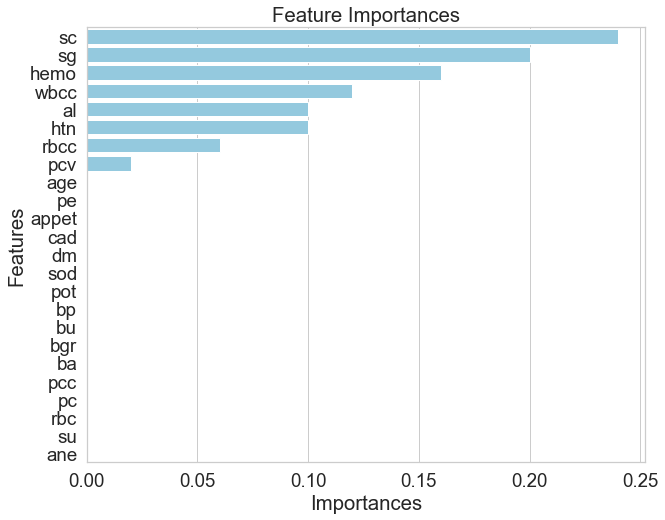

In [39]:
sns.set(font_scale=5)
sns.set(style='whitegrid', color_codes=True, font_scale=1.7)
fig, ax = plt.subplots()
fig.set_size_inches(10, 8)
sns.barplot(x=importances['importance'], y = importances['features'], 
            data= importances, color='skyblue')
plt.xlabel('Importances')
plt.ylabel('Features')
plt.title('Feature Importances')
plt.show()

# Gray-Wolf Optimization Algorithm

In [40]:
def GWO(objf,lb,ub,dim,SearchAgents_no,Max_iter):
    
    # initialize alpha, beta, and delta_pos
    Alpha_pos=np.zeros(dim)
    Alpha_score=float("inf")
    
    Beta_pos=np.zeros(dim)
    Beta_score=float("inf")
    
    Delta_pos=np.zeros(dim)
    Delta_score=float("inf")

    if not isinstance(lb, list):
        lb = [lb] * dim
    if not isinstance(ub, list):
        ub = [ub] * dim
    
    #Initialize the positions of search agents
    Positions = np.zeros((SearchAgents_no, dim))
    for i in range(dim):
        Positions[:, i] = np.random.uniform(0,1, SearchAgents_no) * (ub[i] - lb[i]) + lb[i]
    
    Convergence_curve=np.zeros(Max_iter)

     # Loop counter
    print("GWO is optimizing  \""+objf.__name__+"\"")    

    # Main loop
    for l in range(0,Max_iter):
        for i in range(0,SearchAgents_no):
            
            # Return back the search agents that go beyond the boundaries of the search space
            for j in range(dim):
                Positions[i,j]=np.clip(Positions[i,j], lb[j], ub[j])

            # Calculate objective function for each search agent
            fitness=objf(Positions[i,:])
            
            # Update Alpha, Beta, and Delta
            if fitness<Alpha_score :
                Alpha_score=fitness; # Update alpha
                Alpha_pos=Positions[i,:].copy()
            
            
            if (fitness>Alpha_score and fitness<Beta_score ):
                Beta_score=fitness  # Update beta
                Beta_pos=Positions[i,:].copy()
            
            
            if (fitness>Alpha_score and fitness>Beta_score and fitness<Delta_score): 
                Delta_score=fitness # Update delta
                Delta_pos=Positions[i,:].copy()
        
        a=2-l*((2)/Max_iter); # a decreases linearly fron 2 to 0
        
        # Update the Position of search agents including omegas
        for i in range(0,SearchAgents_no):
            for j in range (0,dim):     
                           
                r1=random.random() # r1 is a random number in [0,1]
                r2=random.random() # r2 is a random number in [0,1]
                
                A1=2*a*r1-a; # Equation (3.3)
                C1=2*r2; # Equation (3.4)
                
                D_alpha=abs(C1*Alpha_pos[j]-Positions[i,j]); # Equation (3.5)-part 1
                X1=Alpha_pos[j]-A1*D_alpha; # Equation (3.6)-part 1
                           
                r1=random.random()
                r2=random.random()
                
                A2=2*a*r1-a; # Equation (3.3)
                C2=2*r2; # Equation (3.4)
                
                D_beta=abs(C2*Beta_pos[j]-Positions[i,j]); # Equation (3.5)-part 2
                X2=Beta_pos[j]-A2*D_beta; # Equation (3.6)-part 2       
                
                r1=random.random()
                r2=random.random() 
                
                A3=2*a*r1-a; # Equation (3.3)
                C3=2*r2; # Equation (3.4)
                
                D_delta=abs(C3*Delta_pos[j]-Positions[i,j]); # Equation (3.5)-part 3
                X3=Delta_pos[j]-A3*D_delta; # Equation (3.5)-part 3             
                
                Positions[i,j]=(X1+X2+X3)/3  # Equation (3.7)        
        Convergence_curve[l]=Alpha_score;

        #if (l%1==0):
               #print(['At iteration '+ str(l)+ ' the best fitness is '+ str(Alpha_score)]);
    
    print(Positions.shape)
    print("Alpha position=",Alpha_pos);
    print("Beta position=",Beta_pos);
    print("Delta position=",Delta_pos);
    return Alpha_pos,Beta_pos;

# Setting GWO parameters

In [63]:
iters=1000
wolves=100
dimension=24
search_domain=[0,1]
lb=-100
ub=100
colneeded=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]
modified_data=pd.DataFrame()
for i in colneeded:
    modified_data[x1.columns[i]]=x1[x1.columns[i]].astype(float)
func_details=benchmarks.getFunctionDetails(6)

for i in range(0,24):
    alpha,beta=GWO(getattr(benchmarks,'F7'),lb,ub,dimension,wolves,iters)

GWO is optimizing  "F7"
(100, 24)
Alpha position= [-5.95467690e-04 -3.23051074e-02 -7.15510422e-02  1.38737551e-02
 -3.02221899e-02 -4.41293908e-02  9.87004910e-03  2.34230466e-02
  7.95618890e-03  3.48649107e-03 -3.03970433e-02 -1.14553128e-02
  2.56681458e-03  5.28776891e-04  3.04130491e-02 -7.38202497e-03
 -1.52700943e-02 -3.61544018e-04 -4.98968548e-02  2.41070575e-02
 -3.57552607e-05 -3.14777653e-02  3.93907282e-03 -6.89158590e-03]
Beta position= [-7.25731800e-04 -3.18678161e-02 -7.45631805e-02  1.25404196e-02
 -3.43783029e-02 -4.09667966e-02  9.00150745e-03  2.19163464e-02
  7.04135494e-03  3.43133985e-03 -3.15298397e-02 -1.23276462e-02
  2.89698729e-03  5.15886987e-04  2.77488319e-02 -7.82860428e-03
 -1.61734004e-02 -3.70782014e-04 -5.11132197e-02  2.55880334e-02
 -3.57861632e-05 -3.15311408e-02  3.73846308e-03 -6.79115869e-03]
Delta position= [-8.54201314e-04 -3.08462219e-02 -7.67356414e-02  1.16235279e-02
 -3.69507633e-02 -3.84528425e-02  8.51950753e-03  2.15516877e-02
  6.291

(100, 24)
Alpha position= [-0.00177553 -0.03161073  0.00403976  0.00558673 -0.00217564 -0.01027217
 -0.04207544  0.03337091 -0.00082015 -0.01384726 -0.00193448 -0.00324369
 -0.00027496 -0.01708641 -0.0013823   0.0004438  -0.0144983   0.00672597
 -0.01058349 -0.02586689 -0.0168723   0.01560757 -0.0069805   0.03037183]
Beta position= [-0.00169655 -0.03235647  0.00255438  0.00547399 -0.00143003 -0.01028926
 -0.04683804  0.03260239 -0.00076721 -0.01633533 -0.00247977 -0.00404924
 -0.00026266 -0.01852402 -0.001561    0.00058028 -0.01533803  0.00640639
 -0.00884696 -0.02880721 -0.01589623  0.01737664 -0.00668726  0.03118129]
Delta position= [-0.00170812 -0.03154837  0.00325021  0.00557228 -0.00173162 -0.01031005
 -0.04620711  0.0321364  -0.00077469 -0.0161307  -0.00233919 -0.00387834
 -0.0002574  -0.01828238 -0.00145769  0.00054055 -0.01481383  0.0067202
 -0.00986609 -0.0282595  -0.01562359  0.01660867 -0.00674749  0.0305861 ]
GWO is optimizing  "F7"
(100, 24)
Alpha position= [ 0.013266   -0

(100, 24)
Alpha position= [ 5.08530397e-02  5.38245106e-03 -3.24974698e-02 -6.28812235e-03
  5.18234254e-02  7.68285435e-03 -9.73288864e-03  3.59894305e-02
 -3.88344749e-03 -1.41262071e-02 -5.78987234e-03 -5.21928497e-02
 -2.38710924e-02 -4.03544804e-02 -4.54019434e-02  9.98623827e-03
  3.42151808e-02 -1.21145089e-02  5.56106108e-03  8.68981474e-05
 -2.45640067e-02  1.79406089e-03 -9.87203628e-03 -4.12088563e-04]
Beta position= [ 5.21958553e-02  5.09334741e-03 -3.16639350e-02 -6.28716014e-03
  5.29108206e-02  8.00231487e-03 -9.99850201e-03  3.43488022e-02
 -3.74730272e-03 -1.39190981e-02 -5.79204647e-03 -5.16711645e-02
 -2.34485824e-02 -4.02319691e-02 -4.53373140e-02  8.96997135e-03
  3.82003464e-02 -1.24447963e-02  5.24854872e-03  9.08224351e-05
 -2.36743285e-02  1.66592559e-03 -9.85005030e-03 -4.24656008e-04]
Delta position= [ 5.33982974e-02  5.05354950e-03 -3.36023406e-02 -6.46618955e-03
  5.88470108e-02  7.85956584e-03 -1.03852948e-02  3.24253074e-02
 -3.03660606e-03 -1.30176451e-0

In [64]:
##Applying feature selection on the given dataset
##considering alpha as best solution and putting a threshold
threshold=-0.05
index=[]
print("alpha shape=",alpha.shape[0])
modified_daata=pd.DataFrame();
for i in range(0,alpha.shape[0]):
    if(alpha[i]>=threshold):
        modified_daata[x1.columns[i]]=x1[x1.columns[i]].astype(float)
print("The modified data is following")
modified_data.head()

alpha shape= 24
The modified data is following


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane
3,48.0,70.0,1.005,4.0,0.0,0.0,1.0,0.0,0.0,117.0,...,11.2,32.0,6700.0,3.9,1.0,0.0,0.0,1.0,1.0,1.0
9,53.0,90.0,1.020,2.0,0.0,1.0,1.0,0.0,0.0,70.0,...,9.5,29.0,12100.0,3.7,1.0,1.0,0.0,1.0,0.0,1.0
11,63.0,70.0,1.010,3.0,0.0,1.0,1.0,0.0,0.0,380.0,...,10.8,32.0,4500.0,3.8,1.0,1.0,0.0,1.0,1.0,0.0
14,68.0,80.0,1.010,3.0,2.0,0.0,1.0,0.0,1.0,157.0,...,5.6,16.0,11000.0,2.6,1.0,1.0,1.0,1.0,1.0,0.0
20,61.0,80.0,1.015,2.0,0.0,1.0,1.0,1.0,0.0,173.0,...,7.7,24.0,9200.0,3.2,1.0,1.0,1.0,1.0,1.0,1.0


In [65]:
xm1=modified_data
xm1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 158 entries, 3 to 399
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     158 non-null    float64
 1   bp      158 non-null    float64
 2   sg      158 non-null    float64
 3   al      158 non-null    float64
 4   su      158 non-null    float64
 5   rbc     158 non-null    float64
 6   pc      158 non-null    float64
 7   pcc     158 non-null    float64
 8   ba      158 non-null    float64
 9   bgr     158 non-null    float64
 10  bu      158 non-null    float64
 11  sc      158 non-null    float64
 12  sod     158 non-null    float64
 13  pot     158 non-null    float64
 14  hemo    158 non-null    float64
 15  pcv     158 non-null    float64
 16  wbcc    158 non-null    float64
 17  rbcc    158 non-null    float64
 18  htn     158 non-null    float64
 19  dm      158 non-null    float64
 20  cad     158 non-null    float64
 21  appet   158 non-null    float64
 22  pe

In [66]:

xm1_train, xm1_test, ym1_train, ym1_test = train_test_split(xm1, y1, test_size = m, random_state = n)

In [67]:
bestfeatures = SelectKBest(score_func=chi2, k=10)
fit = bestfeatures.fit(xm1,y1)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(modified_data.columns)

featureScores = pd.concat([dfcolumns, dfscores], axis=1)
featureScores.columns = ['Specs', 'Score']
featureScores

,Specs,Score
0,age,70.962202
1,bp,28.238424
2,sg,0.002906
3,al,336.976744
4,su,106.976744
5,rbc,48.139535
6,pc,77.558140
7,pcc,3.640181
8,ba,32.093023
9,bgr,1762.030281


In [68]:
# 10 best features
featureScores.nlargest(10, 'Score')

,Specs,Score
16,wbcc,30084.148308
10,bu,3079.959561
9,bgr,1762.030281
3,al,336.976744
11,sc,335.034935
15,pcv,212.873055
4,su,106.976744
18,htn,90.930233
6,pc,77.558140
19,dm,74.883721


In [69]:
bestfeatures = SelectKBest(score_func=chi2, k=10)
fit = bestfeatures.fit(x1,y1)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(x1.columns)

featureScores = pd.concat([dfcolumns, dfscores], axis=1)
featureScores.columns = ['Specs', 'Score']
featureScores
featureScores.nlargest(10, 'Score')

,Specs,Score
16,wbcc,30084.148308
10,bu,3079.959561
9,bgr,1762.030281
3,al,336.976744
11,sc,335.034935
15,pcv,212.873055
4,su,106.976744
18,htn,90.930233
6,pc,77.558140
19,dm,74.883721
